# Day 2 — Training Data Quality & Augmentation

**Objective:**  
- Run quality checks on training/validation/test images  
- Flag/remove low-quality images  
- Apply data augmentation to increase dataset diversity  
- Generate a quality report (`quality_report.csv`)


In [11]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from quality_checks import scan_dataset, save_quality_report, list_images_in_dir
from augmentation import augment_dataset

print("CWD:", os.getcwd())


CWD: /Users/aakashjawle/Desktop/IITB/Week 2/Day 2


In [12]:
data_root = Path("data")

train_dir = data_root / "train"
val_dir   = data_root / "val"
test_dir  = data_root / "test"

print("Train dir exists:", train_dir.exists())
print("Val dir exists:  ", val_dir.exists())
print("Test dir exists: ", test_dir.exists())


Train dir exists: True
Val dir exists:   True
Test dir exists:  True


In [13]:
df_quality = scan_dataset(
    data_root="data",
    splits=["train", "val", "test"],   
    blur_threshold=50.0,
    brightness_range=(60.0, 200.0),
    contrast_threshold=25.0,
    noise_threshold=15.0,
)

print("Number of images scanned:", len(df_quality))
df_quality.head()


[INFO] Found 1951 images in data/train
[INFO] Found 253 images in data/val
[INFO] Found 106 images in data/test
Number of images scanned: 2310


,path,blur_score,brightness,contrast,noise_level,is_blurry,is_too_dark,is_too_bright,is_low_contrast,is_noisy,is_low_quality,split,class
0,data/train/diseased cotton plant/dd (536)_iaip...,457.605233,125.305483,34.695008,4.700591,False,False,False,False,False,False,train,diseased cotton plant
1,data/train/diseased cotton plant/dd (470)_iaip...,312.868721,127.176115,32.228122,3.880967,False,False,False,False,False,False,train,diseased cotton plant
2,data/train/diseased cotton plant/dd (193)_iaip...,674.064647,134.894594,27.599142,5.689632,False,False,False,False,False,False,train,diseased cotton plant
3,data/train/diseased cotton plant/dd (646)_iaip...,115.767409,143.134328,37.067709,2.453133,False,False,False,False,False,False,train,diseased cotton plant
4,data/train/diseased cotton plant/dd (120)_iaip...,417.188537,125.375054,27.161338,4.430255,False,False,False,False,False,False,train,diseased cotton plant


In [14]:
total_images = len(df_quality)
low_quality = df_quality[df_quality["is_low_quality"]]
num_low = len(low_quality)

print(f"Total images:      {total_images}")
print(f"Low-quality images:{num_low} ({(num_low / total_images * 100):.2f}%)")

low_quality.head()


Total images:      2310
Low-quality images:155 (6.71%)


,path,blur_score,brightness,contrast,noise_level,is_blurry,is_too_dark,is_too_bright,is_low_contrast,is_noisy,is_low_quality,split,class
17,data/train/diseased cotton plant/dd (905)_iaip...,29.169004,129.237848,32.040451,1.253328,True,False,False,False,False,True,train,diseased cotton plant
117,data/train/diseased cotton plant/dd (794)_iaip...,39.808833,167.277556,46.186895,1.419203,True,False,False,False,False,True,train,diseased cotton plant
147,data/train/diseased cotton plant/dd (845)_iaip...,25.166472,157.417099,34.795642,1.162526,True,False,False,False,False,True,train,diseased cotton plant
198,data/train/diseased cotton plant/dd (904)_iaip...,23.958243,130.586994,40.593229,1.138195,True,False,False,False,False,True,train,diseased cotton plant
273,data/train/diseased cotton plant/dd (776)_iaip...,27.867816,172.342993,43.312264,1.232931,True,False,False,False,False,True,train,diseased cotton plant


In [15]:
save_quality_report(df_quality, "quality_report.csv")

low_quality.to_csv("quality_report_low_quality_only.csv", index=False)

print("Saved:")
print("- quality_report.csv")
print("- quality_report_low_quality_only.csv")


[INFO] Saved quality report to quality_report.csv
Saved:
- quality_report.csv
- quality_report_low_quality_only.csv


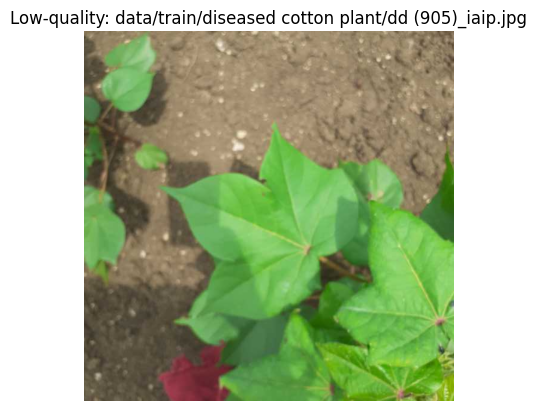

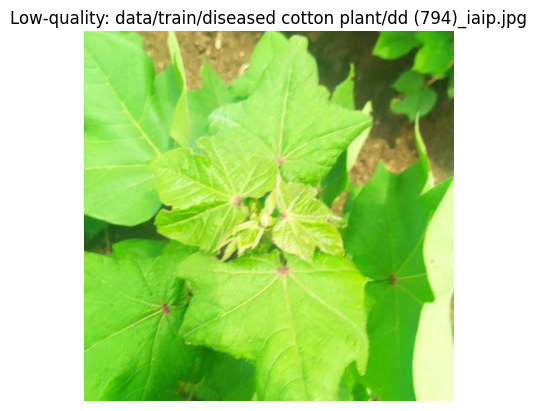

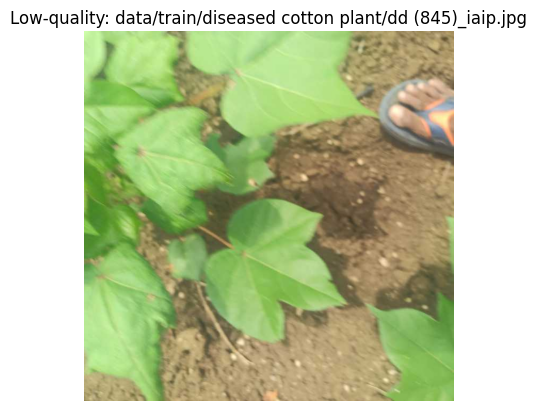

In [16]:
import cv2

def show_image(path, title=""):
    img = cv2.imread(path)
    if img is None:
        print(f"[WARN] Could not read image: {path}")
        return
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.imshow(img)
    plt.axis("off")
    plt.title(title)
    plt.show()

for _, row in low_quality.head(3).iterrows():
    show_image(row["path"], title=f"Low-quality: {row['path']}")


In [17]:
import shutil

low_quality_root = Path("data_low_quality")
low_quality_root.mkdir(exist_ok=True)

for _, row in low_quality.iterrows():
    src = Path(row["path"])
    rel = src.relative_to(data_root)  # train/class/img.png
    dst = low_quality_root / rel
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)

print(f"Copied {len(low_quality)} low-quality images to {low_quality_root}")


Copied 155 low-quality images to data_low_quality


In [18]:
augment_dataset(
    input_root="data/train",        
    output_root="data/train_aug",   
    augmentations_per_image=2       
)


[INFO] Found 1951 images in data/train
[INFO] Augmented images saved to data/train_aug


In [19]:
train_orig = list_images_in_dir(Path("data/train"))
train_aug  = list_images_in_dir(Path("data/train_aug"))

print(f"Original train images:  {len(train_orig)}")
print(f"Augmented train images: {len(train_aug)}")


Original train images:  1951
Augmented train images: 3902


We performed image quality checks across the training, validation, and test datasets. The evaluation included blur detection using variance of Laplacian, as well as brightness, contrast, and noise analysis. Any images failing the thresholds were marked as low quality.

Two reports were generated:
• quality_report.csv containing all images and their metrics
• quality_report_low_quality_only.csv including only the flagged images

In addition, we created an augmented version of the training set. The original images from data/train were expanded and saved to data/train_aug using several augmentation techniques, including flips, rotations, shifts, zooming, random cropping, brightness and contrast adjustments, sharpening, Gaussian noise, and CLAHE for contrast enhancement.